In [53]:
loaded_model = joblib.load(
    "../model/demand_forecasting_model.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


In [52]:
import joblib

joblib.dump(
    rf_model,
    "../model/demand_forecasting_model.pkl"
)

['../model/demand_forecasting_model.pkl']

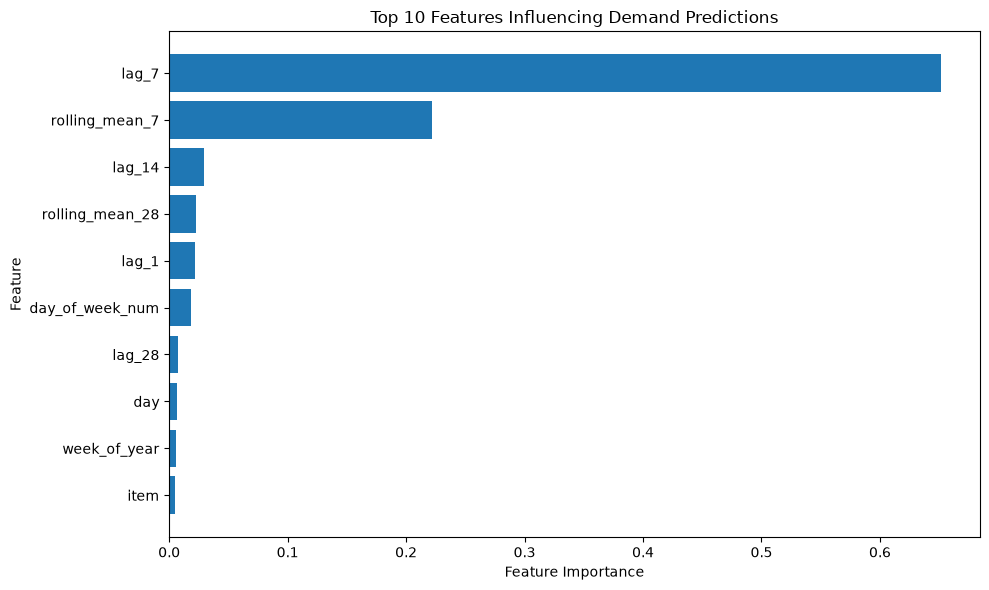

In [51]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 10 Features Influencing Demand Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [50]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
)

feature_importance

,Feature,Importance
9,lag_7,0.651848
12,rolling_mean_7,0.222091
10,lag_14,0.029398
13,rolling_mean_28,0.022808
8,lag_1,0.021956
5,day_of_week_num,0.018692
11,lag_28,0.007539
4,day,0.006694
6,week_of_year,0.006046
1,item,0.004510


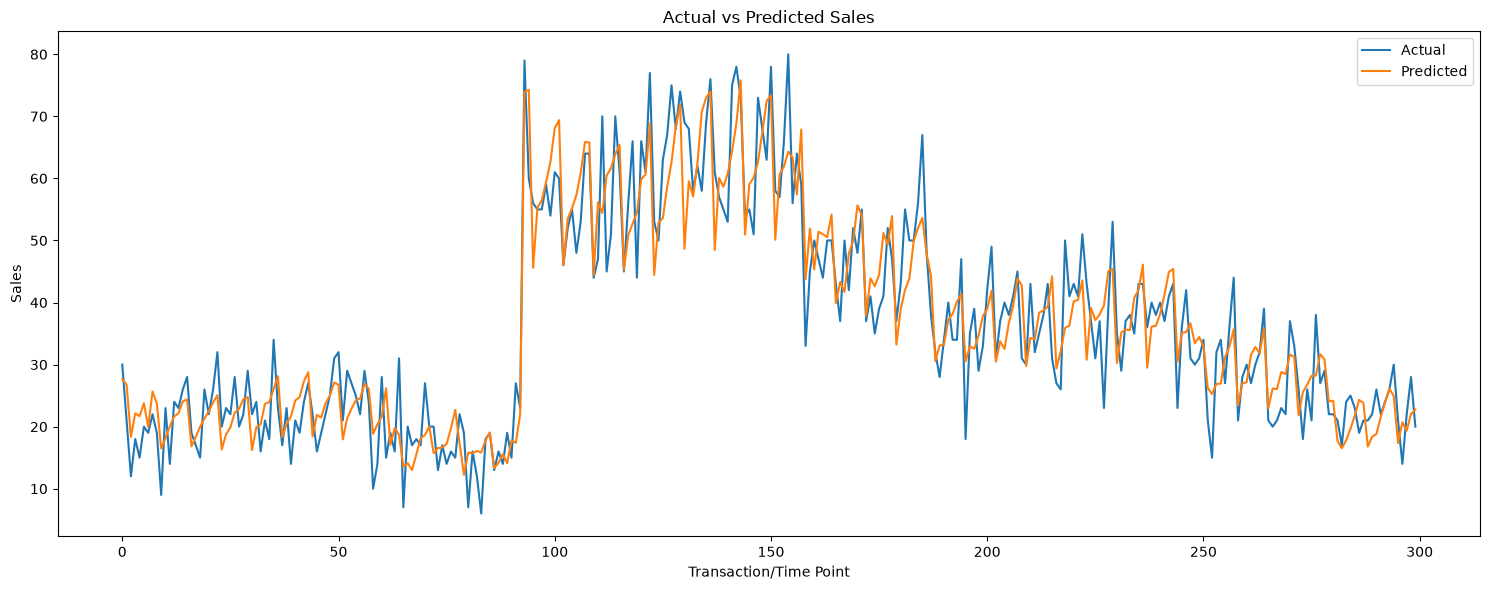

In [49]:
plt.figure(figsize=(15, 6))

plt.plot(
    comparison["Actual"].values[:300],
    label="Actual"
)

plt.plot(
    comparison["Predicted"].values[:300],
    label="Predicted"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Transaction/Time Point")
plt.ylabel("Sales")

plt.legend()
plt.tight_layout()
plt.show()

In [48]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head(20)

,Actual,Predicted
0,30,27.657217
1,21,26.764494
2,12,18.352660
3,18,22.153858
4,15,21.685531
5,20,23.786037
6,19,19.951088
7,22,25.653830
8,19,23.738857
9,9,16.483842


In [54]:
metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Value": [mae, rmse, r2]
})

metrics_df

,Metric,Value
0,MAE,6.191383
1,RMSE,8.067685
2,R²,0.920284


In [47]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("------------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

Model Performance
------------------
MAE : 6.19
RMSE: 8.07
R²  : 0.9203


In [46]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [45]:
y_pred = rf_model.predict(X_test)

y_pred[:10]

array([27.65721698, 26.76449417, 18.35266048, 22.15385824, 21.68553053,
       23.78603723, 19.95108797, 25.65382959, 23.73885697, 16.48384218])

In [44]:
rf_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [43]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

In [42]:
from sklearn.ensemble import RandomForestRegressor

In [41]:
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (852500, 14)
X_test: (46500, 14)


In [40]:
features = [
    "store",
    "item",
    "year",
    "month",
    "day",
    "day_of_week_num",
    "week_of_year",
    "quarter",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]

target = "sales"

In [39]:
train_df = df[df["date"] < test_start].copy()

test_df = df[df["date"] >= test_start].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

Training rows: 852500
Testing rows: 46500


In [38]:
test_start = df["date"].max() - pd.DateOffset(months=3)

print("Test period starts:", test_start)

Test period starts: 2017-09-30 00:00:00


In [37]:
print("Start:", df["date"].min())
print("End:", df["date"].max())

Start: 2013-01-29 00:00:00
End: 2017-12-31 00:00:00


In [36]:
df = df.dropna().reset_index(drop=True)

df.shape

(899000, 17)

In [35]:
df[
    [
        "date",
        "store",
        "item",
        "sales",
        "lag_1",
        "lag_7",
        "lag_14",
        "lag_28",
        "rolling_mean_7",
        "rolling_mean_28"
    ]
].head(40)

,date,store,item,sales,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28
0,2013-01-01,1,1,13,NaN,NaN,NaN,NaN,NaN,NaN
1,2013-01-02,1,1,11,13.0,NaN,NaN,NaN,NaN,NaN
2,2013-01-03,1,1,14,11.0,NaN,NaN,NaN,NaN,NaN
3,2013-01-04,1,1,13,14.0,NaN,NaN,NaN,NaN,NaN
4,2013-01-05,1,1,10,13.0,NaN,NaN,NaN,NaN,NaN
5,2013-01-06,1,1,12,10.0,NaN,NaN,NaN,NaN,NaN
6,2013-01-07,1,1,10,12.0,NaN,NaN,NaN,NaN,NaN
7,2013-01-08,1,1,9,10.0,13.0,NaN,NaN,11.857143,NaN
8,2013-01-09,1,1,12,9.0,11.0,NaN,NaN,11.285714,NaN
9,2013-01-10,1,1,9,12.0,14.0,NaN,NaN,11.428571,NaN


In [34]:
df["rolling_mean_7"] = (
    df.groupby(["store", "item"])["sales"]
      .transform(
          lambda x: x.shift(1).rolling(7).mean()
      )
)

df["rolling_mean_28"] = (
    df.groupby(["store", "item"])["sales"]
      .transform(
          lambda x: x.shift(1).rolling(28).mean()
      )
)

In [33]:
df[
    [
        "date",
        "store",
        "item",
        "sales",
        "lag_1",
        "lag_7",
        "lag_14",
        "lag_28"
    ]
].head(35)

,date,store,item,sales,lag_1,lag_7,lag_14,lag_28
0,2013-01-01,1,1,13,NaN,NaN,NaN,NaN
1,2013-01-02,1,1,11,13.0,NaN,NaN,NaN
2,2013-01-03,1,1,14,11.0,NaN,NaN,NaN
3,2013-01-04,1,1,13,14.0,NaN,NaN,NaN
4,2013-01-05,1,1,10,13.0,NaN,NaN,NaN
5,2013-01-06,1,1,12,10.0,NaN,NaN,NaN
6,2013-01-07,1,1,10,12.0,NaN,NaN,NaN
7,2013-01-08,1,1,9,10.0,13.0,NaN,NaN
8,2013-01-09,1,1,12,9.0,11.0,NaN,NaN
9,2013-01-10,1,1,9,12.0,14.0,NaN,NaN


In [32]:
df["lag_1"] = (
    df.groupby(["store", "item"])["sales"]
      .shift(1)
)

df["lag_7"] = (
    df.groupby(["store", "item"])["sales"]
      .shift(7)
)

df["lag_14"] = (
    df.groupby(["store", "item"])["sales"]
      .shift(14)
)

df["lag_28"] = (
    df.groupby(["store", "item"])["sales"]
      .shift(28)
)

In [31]:
df = df.sort_values(
    ["store", "item", "date"]
).reset_index(drop=True)

df.head()

,date,store,item,sales,day_of_week,month,year,day,day_of_week_num,week_of_year,quarter
0,2013-01-01,1,1,13,Tuesday,1,2013,1,1,1,1
1,2013-01-02,1,1,11,Wednesday,1,2013,2,2,1,1
2,2013-01-03,1,1,14,Thursday,1,2013,3,3,1,1
3,2013-01-04,1,1,13,Friday,1,2013,4,4,1,1
4,2013-01-05,1,1,10,Saturday,1,2013,5,5,1,1


In [30]:
df["day"] = df["date"].dt.day
df["day_of_week_num"] = df["date"].dt.dayofweek
df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)
df["quarter"] = df["date"].dt.quarter

df.head()

,date,store,item,sales,day_of_week,month,year,day,day_of_week_num,week_of_year,quarter
0,2013-01-01,1,1,13,Tuesday,1,2013,1,1,1,1
1,2013-01-02,1,1,11,Wednesday,1,2013,2,2,1,1
2,2013-01-03,1,1,14,Thursday,1,2013,3,3,1,1
3,2013-01-04,1,1,13,Friday,1,2013,4,4,1,1
4,2013-01-05,1,1,10,Saturday,1,2013,5,5,1,1


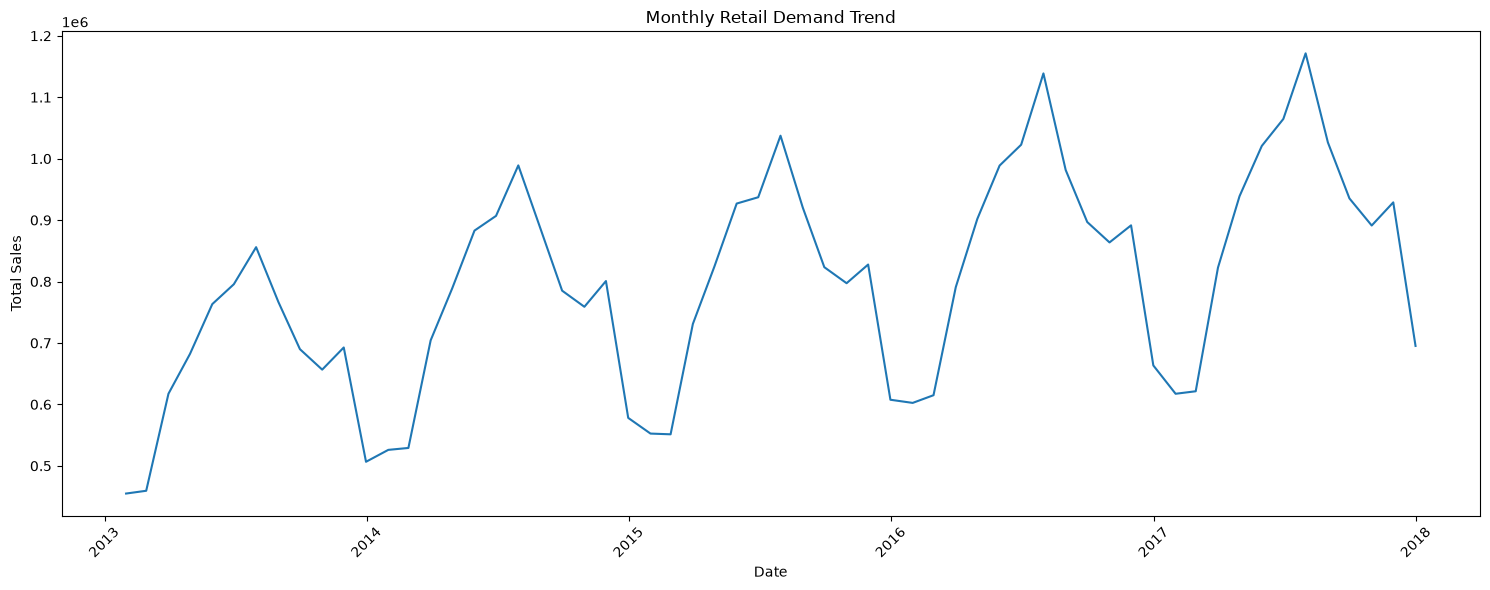

In [29]:
plt.figure(figsize=(15, 6))

plt.plot(monthly_sales)

plt.title("Monthly Retail Demand Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
monthly_sales = (
    df.set_index("date")
      .resample("ME")["sales"]
      .sum()
)

monthly_sales.head()

date
2013-01-31    454904
2013-02-28    459417
2013-03-31    617382
2013-04-30    682274
2013-05-31    763242
Freq: ME, Name: sales, dtype: int64

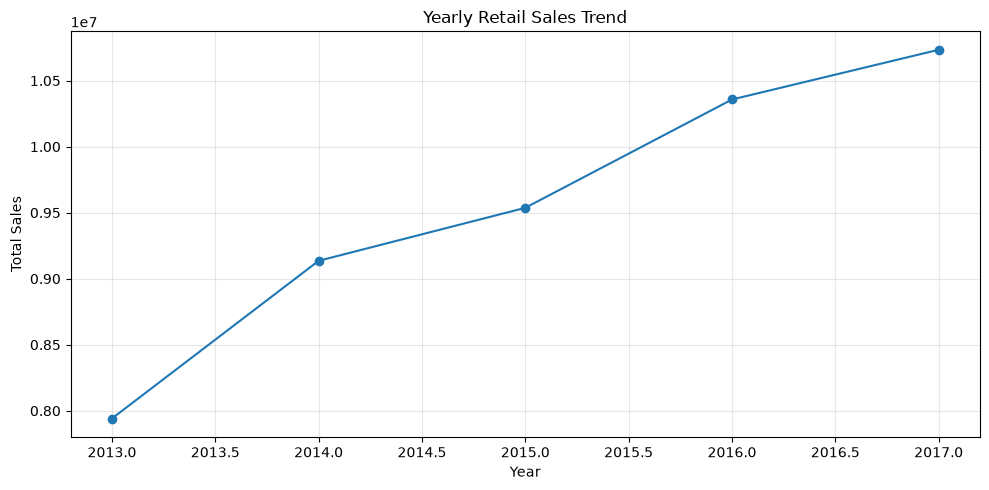

In [27]:
plt.figure(figsize=(10, 5))

yearly_sales.plot(marker="o")

plt.title("Yearly Retail Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
df["year"] = df["date"].dt.year

yearly_sales = (
    df.groupby("year")["sales"]
      .sum()
)

yearly_sales

year
2013     7941243
2014     9135482
2015     9536887
2016    10357160
2017    10733740
Name: sales, dtype: int64

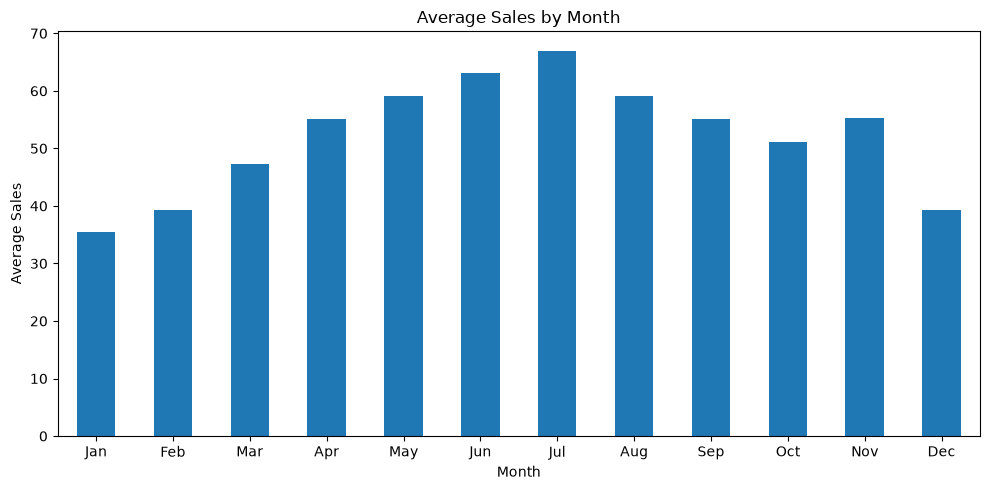

In [25]:
plt.figure(figsize=(10, 5))

monthly_avg.plot(kind="bar")

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")

plt.xticks(
    range(12),
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ],
    rotation=0
)

plt.tight_layout()
plt.show()

In [24]:
df["month"] = df["date"].dt.month

monthly_avg = (
    df.groupby("month")["sales"]
      .mean()
)

monthly_avg

month
1     35.524503
2     39.378397
3     47.305574
4     55.152893
5     59.128219
6     63.025480
7     66.998619
8     59.105226
9     55.072760
10    51.193806
11    55.218080
12    39.365265
Name: sales, dtype: float64

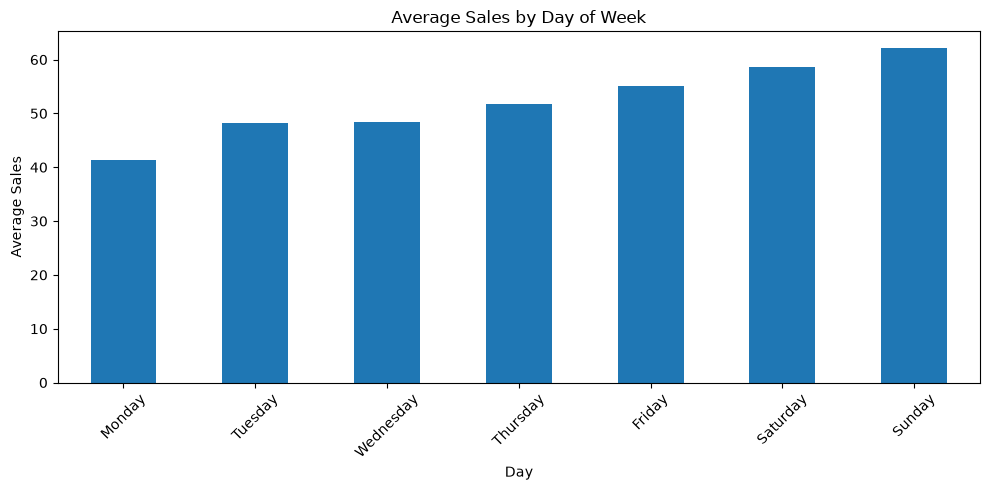

In [23]:
plt.figure(figsize=(10, 5))

weekly_sales.plot(kind="bar")

plt.title("Average Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
df["day_of_week"] = df["date"].dt.day_name()

weekly_sales = (
    df.groupby("day_of_week")["sales"]
      .mean()
      .reindex([
          "Monday",
          "Tuesday",
          "Wednesday",
          "Thursday",
          "Friday",
          "Saturday",
          "Sunday"
      ])
)

weekly_sales

day_of_week
Monday       41.429638
Tuesday      48.225908
Wednesday    48.368506
Thursday     51.723218
Friday       55.157249
Saturday     58.662697
Sunday       62.143333
Name: sales, dtype: float64

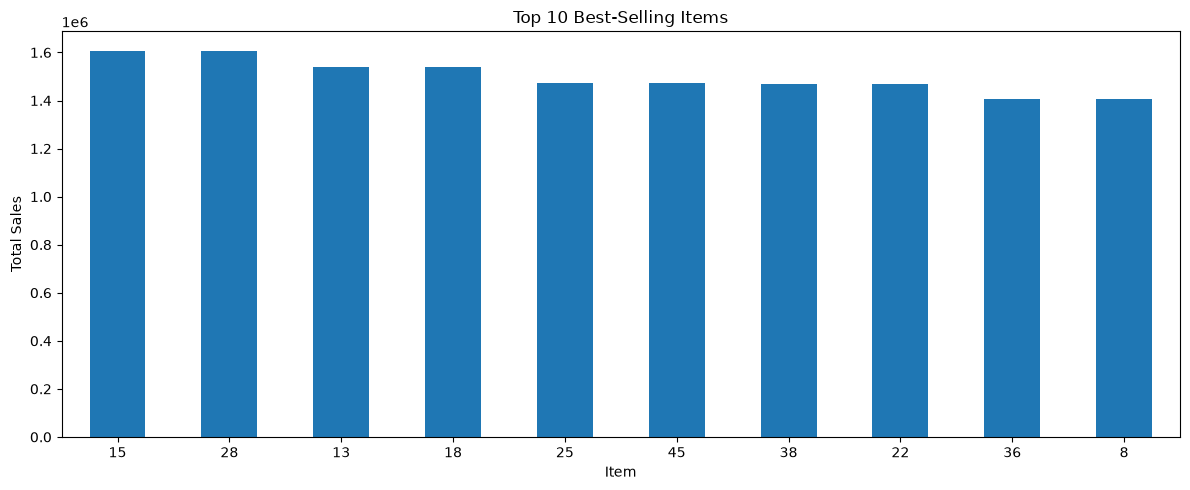

In [21]:
plt.figure(figsize=(12, 5))

item_sales.head(10).plot(kind="bar")

plt.title("Top 10 Best-Selling Items")
plt.xlabel("Item")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
item_sales = (
    df.groupby("item")["sales"]
      .sum()
      .sort_values(ascending=False)
)

item_sales.head(10)

item
15    1607442
28    1604713
13    1539621
18    1538876
25    1473334
45    1471467
38    1470330
22    1469971
36    1406548
8     1405108
Name: sales, dtype: int64

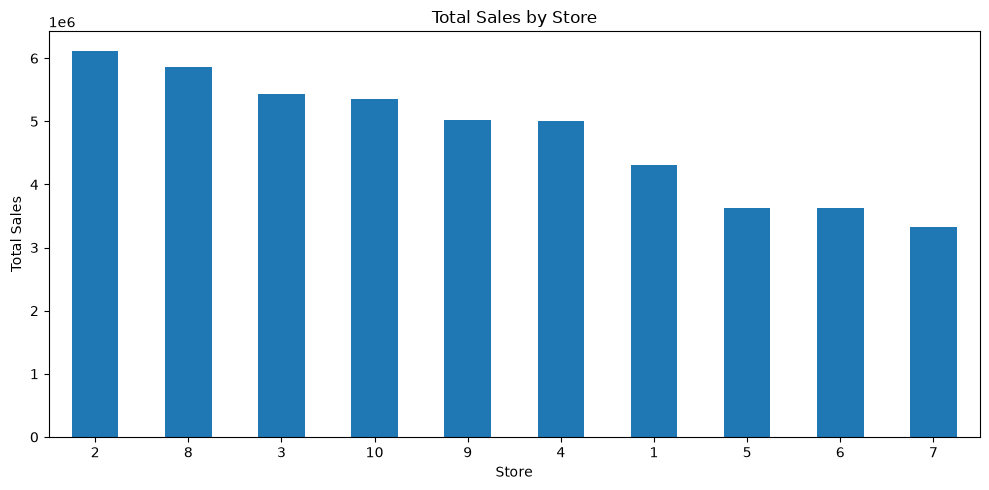

In [19]:
plt.figure(figsize=(10, 5))

store_sales.plot(kind="bar")

plt.title("Total Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
store_sales = (
    df.groupby("store")["sales"]
      .sum()
      .sort_values(ascending=False)
)

store_sales

store
2     6120128
8     5856169
3     5435144
10    5360158
9     5025976
4     5012639
1     4315603
5     3631016
6     3627670
7     3320009
Name: sales, dtype: int64

In [17]:
print("Number of Stores:", df["store"].nunique())
print("Number of Items:", df["item"].nunique())

Number of Stores: 10
Number of Items: 50


In [16]:
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

Start Date: 2013-01-01 00:00:00
End Date: 2017-12-31 00:00:00


In [15]:
df = pd.read_csv("../data/train.csv")

df["date"] = pd.to_datetime(df["date"])

df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [14]:
df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [13]:
df.columns

Index(['date', 'store', 'item', 'sales'], dtype='str')

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 36.6 MB


In [11]:
df.shape

(913000, 4)

In [10]:
df = pd.read_csv("../data/train.csv")

df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns